<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/04_convenio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CARREGAMENTO E INSPEÇÃO INICIAL DOS DADOS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de exibição do Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Carregamento do arquivo CSV
caminho_csv = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/dados/emendas/convenio.csv'
df_raw = pd.read_csv(caminho_csv, sep=';')

print("--- Inspeção Inicial ---")
print(f"Dimensão da base: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")
print("\nInformações sobre colunas e tipos primitivos:")
df_raw.info()


--- Inspeção Inicial ---
Dimensão da base: 17577 linhas e 16 colunas.

Informações sobre colunas e tipos primitivos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17577 entries, 0 to 17576
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Número                      17577 non-null  object 
 1   UF                          17577 non-null  object 
 2   Município                   17577 non-null  object 
 3   Situação                    17577 non-null  object 
 4   Tipo de Instrumento         17577 non-null  object 
 5   Objeto                      17558 non-null  object 
 6   Órgão Superior              17577 non-null  object 
 7   Órgão/Entidade vinculada    17577 non-null  object 
 8   Concedente                  17577 non-null  object 
 9   Convenente                  17577 non-null  object 
 10  Data de início da vigência  17577 non-null  object 
 11  Data de fim da vigência     

# DIAGNÓSTICO E LIMPEZA DOS DADOS (DATA CLEANING)

In [2]:
df = df_raw.copy()

# Eliminação de coluna nula
if 'Unnamed: 15' in df.columns:
    df.drop(columns=['Unnamed: 15'], inplace=True)
    print("\nColuna 'Unnamed: 15' removida.")

# Verificação de registros duplicados
duplicados = df.duplicated().sum()
print(f"Total de linhas duplicadas: {duplicados}")
if duplicados > 0:
    df.drop_duplicates(inplace=True)

# Tratamento e padronização de textos (remoção de espaços extras e caixa alta)
colunas_texto = ['Município', 'Situação', 'Tipo de Instrumento', 'Objeto', 'Órgão Superior']
for col in colunas_texto:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.upper()

# Tratamento de valores ausentes na coluna Objeto
df['Objeto'] = df['Objeto'].fillna('NÃO INFORMADO')



Coluna 'Unnamed: 15' removida.
Total de linhas duplicadas: 0


Higienização da Base:

    A base final conta com 17.577 registros.
    A coluna Unnamed: 15 foi removida.
    Foi verificado que não há linhas duplicadas na base.
    Os campos de moeda foram convertidos para o tipo float64 e as datas para datetime.


# PREPARAÇÃO E TRANSFORMAÇÃO DOS DADOS (DATA WRANGLING)

In [3]:
# Função para conversão de moeda (R$ str -> float)
def converter_moeda_para_float(coluna):
    return pd.to_numeric(
        coluna.astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False),
        errors='coerce'
    )

# Conversão das colunas financeiras
df['Valor_Liberado'] = converter_moeda_para_float(df['Valor Liberado (R$)'])
df['Valor_Celebrado'] = converter_moeda_para_float(df['Valor Celebrado (R$)'])

# Conversão das colunas de data
df['Data_Inicio_Vigencia'] = pd.to_datetime(df['Data de início da vigência'], format='%d/%m/%Y', errors='coerce')
df['Data_Fim_Vigencia'] = pd.to_datetime(df['Data de fim da vigência'], format='%d/%m/%Y', errors='coerce')

# Extração de 'Ano' a partir da vigência inicial
df['Ano_Vigencia'] = df['Data_Inicio_Vigencia'].dt.year

print("\n--- Validação após Transformação ---")
print(df[['Valor_Liberado', 'Valor_Celebrado', 'Ano_Vigencia']].describe())


--- Validação após Transformação ---
       Valor_Liberado  Valor_Celebrado  Ano_Vigencia
count        17577.00         17577.00      17577.00
mean        548408.46        754418.67       2007.94
std        7628386.52       5454785.38          8.10
min              0.00             0.00       1995.00
25%          19992.50         80000.00       2001.00
50%         100000.00        145000.00       2007.00
75%         250000.00        344169.00       2013.00
max      868430271.61     349873247.00       2026.00


Diagnóstico Estatístico (Valores Liberados):

    Mediana (50%): R$ 100.000,00 (metade dos convênios do estado recebem até este valor).
    Média: R$ 548.408,46 (significativamente inflacionada pelos grandes projetos).
    Primeiro Quartil (Q1 - 25%): R$ 19.992,50.
    Terceiro Quartil (Q3 - 75%): R$ 250.000,00.


# ANÁLISE ESTATÍSTICA E CÁLCULO FORMAL DE OUTLIERS (IQR)

In [4]:
# Cálculo estatístico do Limite Superior via Amplitude Interquartil (IQR)
Q1 = df['Valor_Liberado'].quantile(0.25)
Q3 = df['Valor_Liberado'].quantile(0.75)
IQR = Q3 - Q1
limite_superior_iqr = Q3 + (1.5 * IQR)

print(f"\n--- Diagnóstico Estatístico de Outliers ---")
print(f"Q1 (25%): R$ {Q1:,.2f}")
print(f"Q3 (75%): R$ {Q3:,.2f}")
print(f"IQR: R$ {IQR:,.2f}")
print(f"Limite Superior Calculado (Q3 + 1.5*IQR): R$ {limite_superior_iqr:,.2f}")

# Identificação e ordenação dos Outliers
df_outliers = df[df['Valor_Liberado'] > limite_superior_iqr].sort_values(by='Valor_Liberado', ascending=False)
print(f"Total de convênios classificados como outliers estatísticos: {len(df_outliers)}")


--- Diagnóstico Estatístico de Outliers ---
Q1 (25%): R$ 19,992.50
Q3 (75%): R$ 250,000.00
IQR: R$ 230,007.50
Limite Superior Calculado (Q3 + 1.5*IQR): R$ 595,011.25
Total de convênios classificados como outliers estatísticos: 1733


Cálculo Formal de Outliers pelo Método IQR:

    Amplitude Interquartil (IQR): R$ 230.007,50.
    Limite Superior Estatístico (Q3 + 1,5 × IQR): R$ 595.011,25.
    Volume de Outliers: 1.733 convênios (representando cerca de 9,86% de todos os projetos do estado, referentes a obras estruturantes de grande porte).

# EXEMPLO COM A CAPITAL DO RN


In [5]:
# Consolidação anual dos repasses liberados para a capital NATAL
natal_df = df[df['Município'] == 'NATAL']
natal_anual = natal_df.groupby('Ano_Vigencia', as_index=False)['Valor_Liberado'].sum()
natal_anual.rename(columns={'Valor_Liberado': 'Total_Liberado_R$'}, inplace=True)

print("\n--- Repasses Consolidados Anuais para NATAL (Primeiros Anos) ---")
print(natal_anual.head(32))


--- Repasses Consolidados Anuais para NATAL (Primeiros Anos) ---
    Ano_Vigencia  Total_Liberado_R$
0           1995         3113172.75
1           1996        91955048.35
2           1997        97267403.59
3           1998       105114011.01
4           1999       302386530.14
5           2000       133195769.39
6           2001       124347947.10
7           2002        61889590.55
8           2003        74651193.50
9           2004       299577203.87
10          2005       168698745.17
11          2006       185980098.88
12          2007       403953866.99
13          2008       364460589.27
14          2009       407079000.80
15          2010       188598480.23
16          2011       235728061.81
17          2012       281474214.41
18          2013      1547690367.40
19          2014       153924321.24
20          2015        42981766.85
21          2016        22982898.40
22          2017        44597475.91
23          2018       107082961.67
24          2019       131417542.7

# VISUALIZAÇÃO GRÁFICA DE DADOS

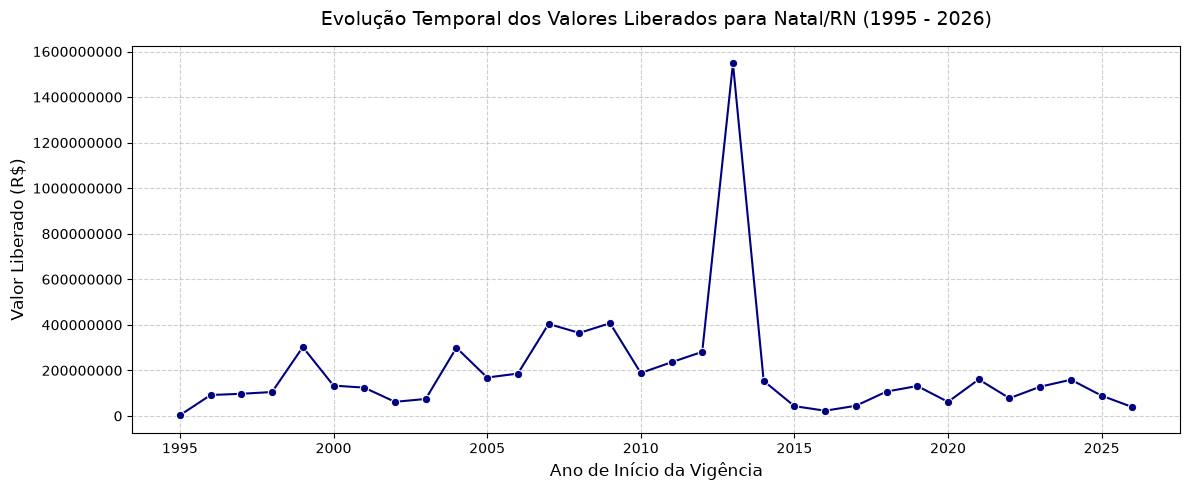

In [6]:
# SEABORN
plt.figure(figsize=(12, 5))
sns.lineplot(data=natal_anual, x='Ano_Vigencia', y='Total_Liberado_R$', marker='o', color='navy')
plt.title('Evolução Temporal dos Valores Liberados para Natal/RN (1995 - 2026)', fontsize=14, pad=15)
plt.xlabel('Ano de Início da Vigência', fontsize=12)
plt.ylabel('Valor Liberado (R$)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

Série Temporal de Natal (1995–2026):

    O gráfico gerado via Seaborn confirma visualmente o pico atípico de repasses em 2013 (R$ 1,55 bilhão)
  

In [7]:
#  Municípios que mais receberam recursos no RN
municipios_mais_recebem = (
    df.groupby('Município')['Valor_Liberado']
    .sum()
    .reset_index()
    .sort_values(by='Valor_Liberado', ascending=False)
    .head(10)
)

print("--- Volume Total de Repasses (RN) ---")
for idx, row in municipios_mais_recebem.iterrows():
    print(f"{row['Município']}: R$ {row['Valor_Liberado']:,.2f}")

--- Volume Total de Repasses (RN) ---
NATAL: R$ 6,295,402,464.04
MOSSORÓ: R$ 421,249,590.89
PARNAMIRIM: R$ 233,395,713.36
SÃO GONÇALO DO AMARANTE: R$ 186,690,688.27
SANTA CRUZ: R$ 72,602,996.53
CAICÓ: R$ 67,591,439.43
MACAÍBA: R$ 61,028,966.17
CEARÁ-MIRIM: R$ 59,128,698.43
EXTREMOZ: R$ 52,401,316.34
AÇU: R$ 45,315,472.60


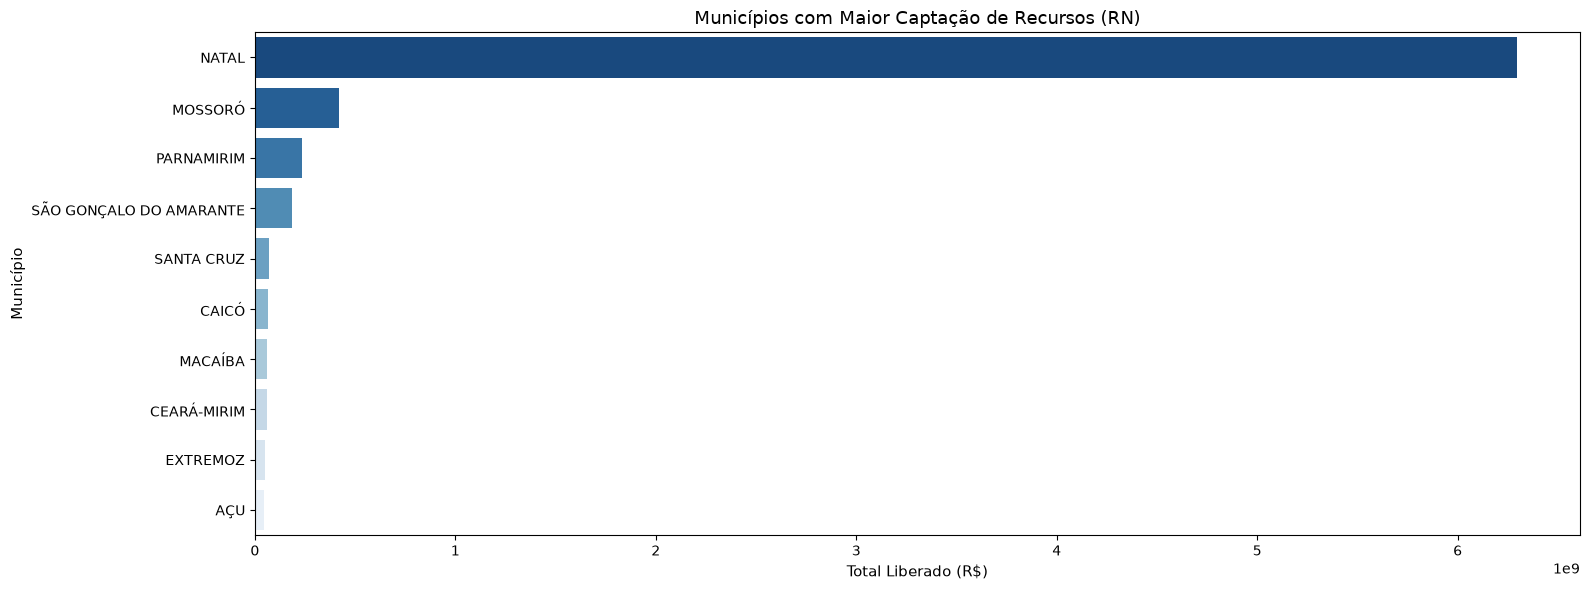

In [8]:
# Gráfico Municípios que mais receberam recursos no RN

fig, axes = plt.subplots(figsize=(16, 6))

sns.barplot(
    data=municipios_mais_recebem,
    y='Município',
    x='Valor_Liberado',
    hue='Município',
    palette='Blues_r',
    legend=False,
    ax=axes
)

axes.set_title('Municípios com Maior Captação de Recursos (RN)', fontsize=13)
axes.set_xlabel('Total Liberado (R$)', fontsize=11)
axes.set_ylabel('Município', fontsize=11)

plt.tight_layout()
plt.show()

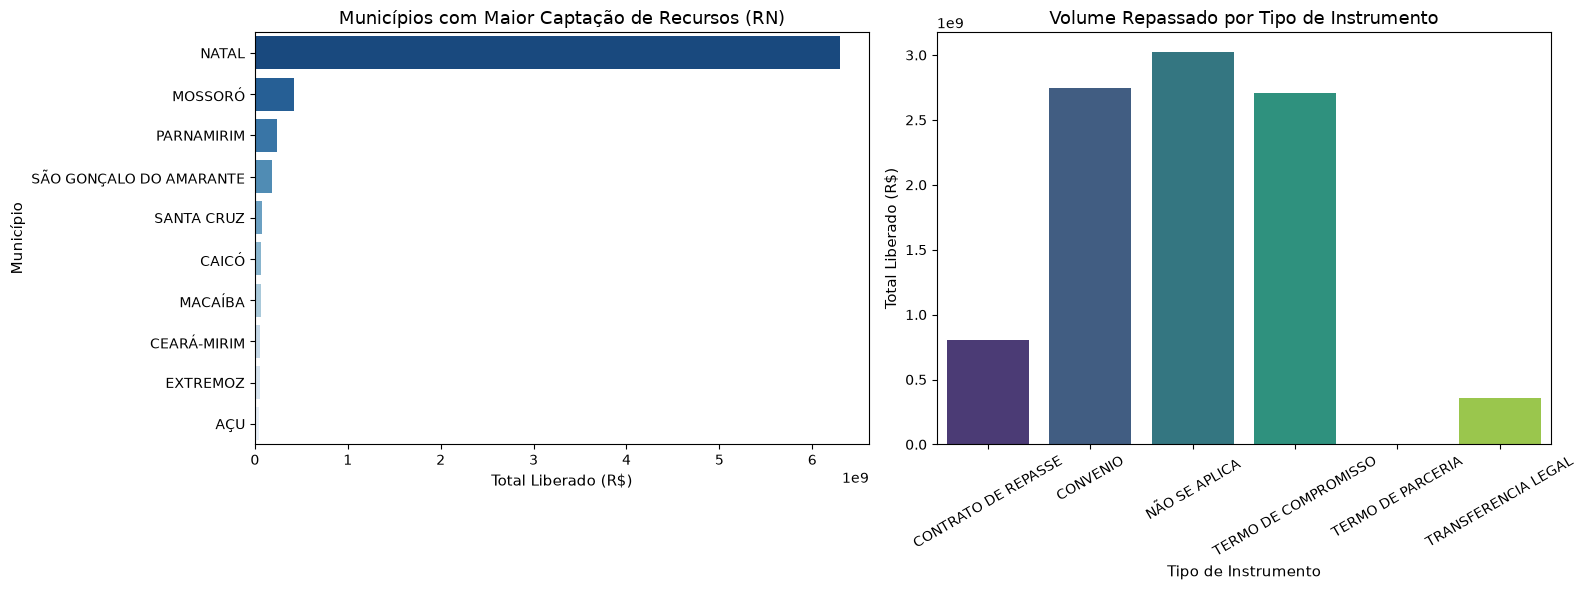

In [9]:
# Criando dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Municípios que mais receberam recursos no RN
sns.barplot(
    data=municipios_mais_recebem,
    y='Município',
    x='Valor_Liberado',
    hue='Município',
    palette='Blues_r',
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    'Municípios com Maior Captação de Recursos (RN)',
    fontsize=13
)
axes[0].set_xlabel('Total Liberado (R$)', fontsize=11)
axes[0].set_ylabel('Município', fontsize=11)

# Gráfico 2: Distribuição por Tipo de Instrumento
instrumento_df = df.groupby(
    'Tipo de Instrumento'
)['Valor_Liberado'].sum().reset_index()

sns.barplot(
    data=instrumento_df,
    x='Tipo de Instrumento',
    y='Valor_Liberado',
    hue='Tipo de Instrumento',
    palette='viridis',
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    'Volume Repassado por Tipo de Instrumento',
    fontsize=13
)
axes[1].set_ylabel('Total Liberado (R$)', fontsize=11)
axes[1].set_xlabel('Tipo de Instrumento', fontsize=11)
axes[1].tick_params(axis='x', rotation=30)

# Ajustando o espaçamento
plt.tight_layout()
plt.show()

In [10]:
# Municípios que menos receberam recursos no RN
municipios_menos_recebem = (
    df.groupby('Município')['Valor_Liberado']
    .sum()
    .reset_index()
    .sort_values(by='Valor_Liberado', ascending=True)
    .head(10)
)

print("--- Menor Volume de Repasses (RN) ---")
for idx, row in municipios_menos_recebem.iterrows():
    print(f"{row['Município']}: R$ {row['Valor_Liberado']:,.2f}")

--- Menor Volume de Repasses (RN) ---
PEDRA PRETA: R$ 3,032,556.91
VILA FLOR: R$ 3,346,975.70
BARCELONA: R$ 3,548,120.40
RIO DO FOGO: R$ 3,909,689.70
PASSAGEM: R$ 4,040,463.91
CORONEL JOÃO PESSOA: R$ 4,366,799.02
MACAU: R$ 4,660,596.42
FRANCISCO DANTAS: R$ 4,799,351.19
IPUEIRA: R$ 4,830,901.24
FERNANDO PEDROZA: R$ 4,887,639.63


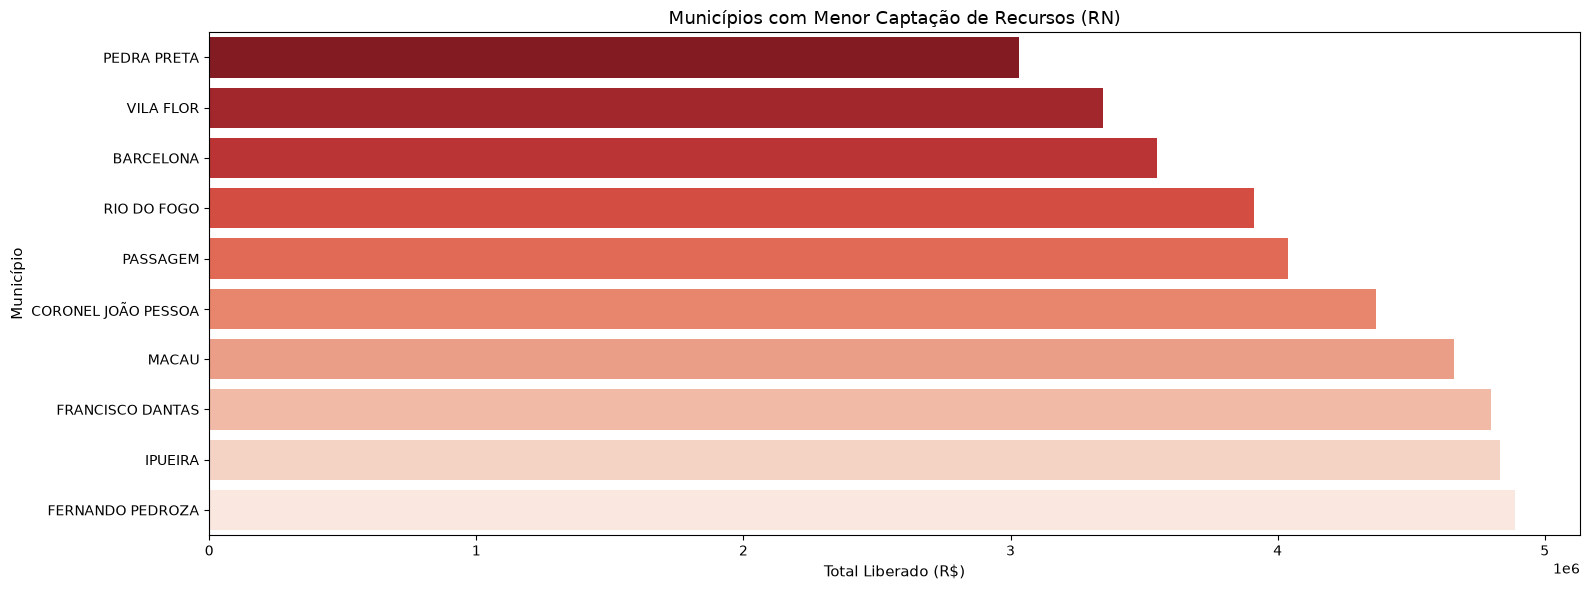

In [11]:
# Gráfico Municípios que menos receberam recursos no RN

fig, axes = plt.subplots(figsize=(16, 6))

sns.barplot(
    data=municipios_menos_recebem,
    y='Município',
    x='Valor_Liberado',
    hue='Município',
    palette='Reds_r',
    legend=False,
    ax=axes
)

axes.set_title('Municípios com Menor Captação de Recursos (RN)', fontsize=13)
axes.set_xlabel('Total Liberado (R$)', fontsize=11)
axes.set_ylabel('Município', fontsize=11)

plt.tight_layout()
plt.show()

Com os 1.733 convênios de grande porte isolados na variável df_outliers
, o próximo passo é identificar quais Ministérios/Órgãos concentram esses recursos.

In [12]:
outliers_por_orgao = (
    df_outliers.groupby('Órgão Superior')['Valor_Liberado']
    .agg(Qtd_Convenios='count', Total_Liberado='sum')
    .reset_index()
    .sort_values(by='Total_Liberado', ascending=False)
)

print("--- Concentração de Grandes Projetos por Ministério/Órgão ---")
print(outliers_por_orgao.head(10))

--- Concentração de Grandes Projetos por Ministério/Órgão ---
                                       Órgão Superior  Qtd_Convenios  \
5   MINISTÉRIO DA INTEGRAÇÃO E DO DESENVOLVIMENTO ...            222   
9                              MINISTÉRIO DAS CIDADES            300   
3                              MINISTÉRIO DA EDUCAÇÃO            334   
1        MINISTÉRIO DA CIÊNCIA, TECNOLOGIA E INOVAÇÃO            155   
8                                 MINISTÉRIO DA SAÚDE            217   
16  MINISTÉRIO DO DESENVOLVIMENTO E ASSISTÊNCIA SO...             42   
6           MINISTÉRIO DA JUSTIÇA E SEGURANÇA PÚBLICA             94   
22                              MINISTÉRIO DO TURISMO             94   
24                         MINISTÉRIO DOS TRANSPORTES              8   
0                MINISTÉRIO DA AGRICULTURA E PECUÁRIA             82   

    Total_Liberado  
5    2167314467.16  
9    1736389262.67  
3     786812922.28  
1     492694838.06  
8     483262979.75  
16    350146468.22 

Identificar a saúde financeira dos projetos públicos no RN, verificando o volume de recursos parados ou em situação crítica de inadimplência.

In [13]:
# Agrupamento do valor total e quantidade de convênios por Situação Administrativa

situacao_risco = (
    df.groupby('Situação')['Valor_Liberado']
    .agg(
        Qtd='count',
        **{'Total_R$': 'sum'}
    )
    .reset_index()
    .sort_values(by='Total_R$', ascending=False)
)

print("--- Diagnóstico de Saúde dos Convênios (Situação Administrativa) ---")
print(situacao_risco)

--- Diagnóstico de Saúde dos Convênios (Situação Administrativa) ---
                                        Situação   Qtd      Total_R$
0                                     ADIMPLENTE   609 3428272528.61
6                                      CONCLUÍDO  8841 2641081260.29
12                                        NORMAL  2754 1331545096.94
8                                    EM EXECUÇÃO  1382 1067285121.81
2                                      ARQUIVADO   622  231494507.43
13                  PRESTAÇÃO DE CONTAS APROVADA   765  203184267.90
11                        INADIMPLÊNCIA SUSPENSA   654  173718926.13
1                 AGUARDANDO PRESTAÇÃO DE CONTAS   115   86086714.97
16         PRESTAÇÃO DE CONTAS EM COMPLEMENTAÇÃO    45   77772344.65
10                                  INADIMPLENTE    99   71734288.25
15                PRESTAÇÃO DE CONTAS EM ANÁLISE   130   69914213.22
17      PRESTAÇÃO DE CONTAS ENVIADA PARA ANÁLISE   167   63989588.82
4                                 

In [14]:
# Identificando convênios ou registros agregados com valor liberado zerado
convenios_zerados = df[df['Valor_Liberado'] == 0]
qtd_zerados = len(convenios_zerados)

print(f"\nTotal de registros de convênios com Valor Liberado igual a R$ 0,00: {qtd_zerados}")


Total de registros de convênios com Valor Liberado igual a R$ 0,00: 3024
